# June 2019 event correction -- Phase 3 (T27-T39) real-data pipeline

Reruns the EXACT same T27-T39 real-data pipeline the October-anchored notebooks
(`T37_clustering_check.ipynb`/`T38_uncertainty_check.ipynb`/
`T39_visualization_comparison.ipynb`) already used, unmodified, against the NEW June
2019 particle history (`result/stage3_particle_history_june2019.npz`, produced by
`T_june2019_stage3_run.ipynb`). No formula, weight, clustering parameter, or
uncertainty parameter is changed -- only the input particle history and t_obs.

All outputs are saved under `result/` -- the existing October outputs under
`results/actual_data/` are never read or overwritten by this notebook.

In [1]:
import os, sys, time
REPO_ROOT = os.path.abspath(os.path.join(os.getcwd(), os.pardir))
if REPO_ROOT not in sys.path:
    sys.path.insert(0, REPO_ROOT)

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.spatial import ConvexHull, QhullError

from iste.ensemble_run import EnsembleRunRecords
from iste.analysis_grid import generate_analysis_grid
from iste.candidate_extraction import CandidateExtractionConfig, find_candidate_peaks
from iste.kdtree_neighborhood import build_particle_neighborhood_index, project_to_local_metres
from iste.particle_query import query_particle_slice
from iste.support_features import SupportFeatureConfig, compute_support_map
from iste.phase3_composite import DEFAULT_WEIGHTS, compute_source_scores_for_candidates
from iste.phase3_clustering import DEFAULT_EPS_M, cluster_candidates
from iste.phase3_uncertainty import (
    DEFAULT_TOTAL_TIMESTAMPS, DEFAULT_SPATIAL_PERCENTILE, BootstrapConfig,
    compute_cluster_uncertainty_table, run_bootstrap_stability,
)
from iste.phase3_diagnostics import compute_diagnostics_table
from iste.phase3_persistence import track_candidate_persistence

RESULT_DIR = os.path.join(REPO_ROOT, "result")
os.makedirs(RESULT_DIR, exist_ok=True)

## 1. Load the June 2019 particle history + observation

In [2]:
spill_data = json.load(open(os.path.join(REPO_ROOT, "data", "database_payload.json"), encoding="utf-8"))
spill = next(s for s in spill_data["spills"] if s["image_filename"] == "ow-0008.jpg")
parcels = spill["parcels"]
obs_lat = np.array([p["lat"] for p in parcels])
obs_lon = np.array([p["lon"] for p in parcels])
obs_ref_lat, obs_ref_lon = float(np.mean(obs_lat)), float(np.mean(obs_lon))

history_path = os.path.join(RESULT_DIR, "stage3_particle_history_june2019.npz")
cached = np.load(history_path, allow_pickle=True)

def _none_if_empty(arr):
    return None if arr.size == 0 else arr

records = EnsembleRunRecords(
    particle_id=cached["particle_id"], forcing_member_id=cached["forcing_member_id"],
    observation_pixel_id=cached["observation_pixel_id"], timestamp=cached["timestamp"],
    lat=cached["lat"], lon=cached["lon"], log_weight=cached["log_weight"], valid=cached["valid"],
    death_time=_none_if_empty(cached["death_time"]), death_lat=_none_if_empty(cached["death_lat"]),
    death_lon=_none_if_empty(cached["death_lon"]), death_reason=_none_if_empty(cached["death_reason"]),
    survival_mark=_none_if_empty(cached["survival_mark"]),
)
t_obs = np.datetime64(np.max(records.timestamp), "ns")
assert t_obs == np.datetime64("2019-06-14T20:35:58", "ns"), t_obs
grid = generate_analysis_grid(t_obs, window_hours=72.0, interval_hours=1.0)
historical_timestamps = grid[1:]
assert len(grid) == 73
assert grid[0] == t_obs
assert grid[-1] == t_obs - np.timedelta64(72, "h") == np.datetime64("2019-06-11T20:35:58", "ns")
print(f"loaded {records.n_records} June-2019 real rows; full analysis grid has {len(grid)} timestamps")
print(f"T0  = {grid[0]}")
print(f"T72 = {grid[-1]}")
assert not any(str(t)[:7] == "2019-10" for t in grid), "October timestamps found in the new analysis grid!"
print("confirmed: zero October timestamps in the new June 2019 analysis grid")

loaded 240024 June-2019 real rows; full analysis grid has 73 timestamps
T0  = 2019-06-14T20:35:58.000000000
T72 = 2019-06-11T20:35:58.000000000
confirmed: zero October timestamps in the new June 2019 analysis grid


## 2. Regenerate candidates + T36 scores + T37 clusters + T38 uncertainty (June particle history)

In [3]:
lat_min = min(spill["bounding_box"]["upper_left"]["lat"], spill["bounding_box"]["bottom_right"]["lat"], float(records.lat[records.valid].min()))
lat_max = max(spill["bounding_box"]["upper_left"]["lat"], spill["bounding_box"]["bottom_right"]["lat"], float(records.lat[records.valid].max()))
lon_min = min(spill["bounding_box"]["upper_left"]["lon"], spill["bounding_box"]["bottom_right"]["lon"], float(records.lon[records.valid].min()))
lon_max = max(spill["bounding_box"]["upper_left"]["lon"], spill["bounding_box"]["bottom_right"]["lon"], float(records.lon[records.valid].max()))
PAD_DEG = 0.03
support_lat_grid = np.arange(lat_min - PAD_DEG, lat_max + PAD_DEG, 0.003)
support_lon_grid = np.arange(lon_min - PAD_DEG, lon_max + PAD_DEG, 0.003)
NEIGHBORHOOD_RADIUS_M = 1000.0
support_config = SupportFeatureConfig()
extraction_config = CandidateExtractionConfig(peak_neighborhood_cells=5, min_separation_m=1500.0, core_radius_m=1000.0)
lon_mesh, lat_mesh = np.meshgrid(support_lon_grid, support_lat_grid)

t0 = time.time()
all_candidates = []
support_grids_by_t_s = {}
envelope_lat, envelope_lon = [], []
for t_s in historical_timestamps:
    slice_ = query_particle_slice(records, t_s)
    envelope_lat.append(slice_.lat[slice_.valid]); envelope_lon.append(slice_.lon[slice_.valid])
    index = build_particle_neighborhood_index(slice_)
    support_map = compute_support_map(
        index, lat_mesh.ravel(), lon_mesh.ravel(), radius_m=NEIGHBORHOOD_RADIUS_M, config=support_config,
    )
    grid_vals = np.array([sf.support for sf in support_map]).reshape(len(support_lat_grid), len(support_lon_grid))
    support_grids_by_t_s[np.datetime64(t_s, "ns")] = grid_vals
    all_candidates.extend(find_candidate_peaks(support_map, support_lat_grid, support_lon_grid, t_s, config=extraction_config))
t1 = time.time()
envelope_lat = np.concatenate(envelope_lat); envelope_lon = np.concatenate(envelope_lon)
print(f"regenerated {len(all_candidates)} June-2019 real candidates in {t1-t0:.1f}s; pooled {len(envelope_lat)} valid particle positions")

regenerated 271 June-2019 real candidates in 80.4s; pooled 236736 valid particle positions


In [4]:
t2 = time.time()
default_scores = compute_source_scores_for_candidates(
    records, all_candidates, support_grids_by_t_s, neighborhood_radius_m=NEIGHBORHOOD_RADIUS_M,
    weights=DEFAULT_WEIGHTS,
)
clusters = cluster_candidates(all_candidates, default_scores, eps_m=DEFAULT_EPS_M)
t3 = time.time()
print(f"computed T36 scores + T37 clusters ({len(clusters)} clusters) in {t3-t2:.1f}s")

bootstrap_result = run_bootstrap_stability(
    all_candidates, default_scores, clusters, config=BootstrapConfig(n_replicates=200, random_seed=42, top_k=10),
)
uncertainty_table = compute_cluster_uncertainty_table(
    clusters, all_candidates, default_scores, records,
    total_timestamps=DEFAULT_TOTAL_TIMESTAMPS, spatial_percentile=DEFAULT_SPATIAL_PERCENTILE,
    bootstrap_result=bootstrap_result,
)
uncertainty_by_cluster = {r.cluster_id: r for r in uncertainty_table}
print(f"computed T38 uncertainty for {len(uncertainty_table)} clusters (bootstrap runtime {bootstrap_result.runtime_seconds:.2f}s)")

computed T36 scores + T37 clusters (4 clusters) in 49.5s


computed T38 uncertainty for 4 clusters (bootstrap runtime 4.09s)


## 3. Full T37 cluster table (June 2019)

In [5]:
rows = []
for cl in clusters:
    unc = uncertainty_by_cluster[cl.cluster_id]
    rows.append(dict(
        cluster_id=cl.cluster_id, n_members=cl.n_members,
        centroid_lat=round(cl.centroid_lat, 5), centroid_lon=round(cl.centroid_lon, 5),
        spatial_radius_km=round(cl.spatial_radius_m / 1000.0, 3),
        uncertainty_radius_km=round(unc.uncertainty_radius_km, 3),
        n_distinct_timestamps=cl.n_distinct_timestamps,
        temporal_span_hours=round(cl.temporal_span_hours, 1),
        temporal_uncertainty_hours=round(unc.temporal_uncertainty_hours, 2),
        particle_support_fraction=round(unc.particle_support_fraction, 5),
        persistence_fraction=round(unc.persistence_fraction, 4),
        mean_source_score=round(cl.mean_source_score, 4),
        peak_source_score=round(cl.peak_source_score, 4),
        candidate_stability_percent=(
            round(unc.candidate_stability_percent, 1) if unc.candidate_stability_percent is not None else "unavailable"
        ),
        ais_status=unc.ais_status,
    ))
cluster_df = pd.DataFrame(rows)
print(cluster_df.to_string(index=False))
cluster_df.to_csv(os.path.join(RESULT_DIR, "june2019_cluster_table.csv"), index=False)

 cluster_id  n_members  centroid_lat  centroid_lon  spatial_radius_km  uncertainty_radius_km  n_distinct_timestamps  temporal_span_hours  temporal_uncertainty_hours  particle_support_fraction  persistence_fraction  mean_source_score  peak_source_score  candidate_stability_percent  ais_status
cluster0000        267      34.31432      35.11652             29.558                 30.073                     72                 71.0                       19.83                    0.91089                0.9863             0.5414             1.1931                        100.0 unavailable
cluster0003          1      34.32855      34.95546              0.000                  0.919                      1                  0.0                        0.00                    0.00061                0.0137             0.2949             0.2949                          0.0 unavailable
cluster0002          2      34.23855      35.29746              0.866                  0.677                      2      

## 4. Old-vs-new ranking comparison (June 2019 event)

In [6]:
tracks = track_candidate_persistence(all_candidates)
track_by_candidate_id = {}
for tr in tracks:
    for cid in tr.candidate_ids:
        track_by_candidate_id[cid] = tr

old_ranked = sorted(all_candidates, key=lambda c: -c.support_score)
old_rank_by_id = {c.candidate_id: i + 1 for i, c in enumerate(old_ranked)}
scores_by_id = {s.candidate_id: s for s in default_scores}
new_ranked = sorted(all_candidates, key=lambda c: -scores_by_id[c.candidate_id].source_score)
new_rank_by_id = {c.candidate_id: i + 1 for i, c in enumerate(new_ranked)}
old_top10_ids = {c.candidate_id for c in old_ranked[:10]}
new_top10_ids = {c.candidate_id for c in new_ranked[:10]}
union_ids = old_top10_ids | new_top10_ids
candidates_by_id = {c.candidate_id: c for c in all_candidates}

rows = []
for cid in union_ids:
    c = candidates_by_id[cid]
    s = scores_by_id[cid]
    track = track_by_candidate_id.get(cid)
    dist_x, dist_y = project_to_local_metres(c.y_peak, c.x_peak, lat_ref=obs_ref_lat, lon_ref=obs_ref_lon)
    dist_km = float(np.sqrt(dist_x[0]**2 + dist_y[0]**2)) / 1000.0
    rows.append(dict(
        candidate_id=cid, old_rank=old_rank_by_id[cid], new_rank=new_rank_by_id[cid],
        old_score=round(c.support_score, 4), new_score=round(s.source_score, 4),
        support_duration_hours=round(track.persistence_duration_hours, 1) if track is not None else 0.0,
        distance_from_observed_km=round(dist_km, 2), particle_support=int(c.density_score),
        AIS_support=("unavailable" if s.ais_evidence is None else round(s.ais_evidence, 4)),
        screening_support=round(s.support_evidence, 4),
    ))
comparison_df = pd.DataFrame(rows).sort_values("new_rank").reset_index(drop=True)
print(comparison_df.to_string(index=False))
comparison_df.to_csv(os.path.join(RESULT_DIR, "june2019_old_vs_new_ranking.csv"), index=False)
print(f"top-10 overlap (old vs new): {len(old_top10_ids & new_top10_ids)}/10")

               candidate_id  old_rank  new_rank  old_score  new_score  support_duration_hours  distance_from_observed_km  particle_support AIS_support  screening_support
2019-06-12T04:35:58_cand000        61         1  1110.2424     1.1931                    71.0                      38.63               374 unavailable             1.4538
2019-06-12T02:35:58_cand000        65         2  1074.1755     1.1896                    71.0                      39.65               356 unavailable             1.4491
2019-06-12T07:35:58_cand000        52         3  1177.3365     1.1843                    71.0                      36.21               417 unavailable             1.4320
2019-06-12T06:35:58_cand000        54         4  1159.4605     1.1813                    71.0                      37.07               405 unavailable             1.4219
2019-06-12T05:35:58_cand000        60         5  1113.3267     1.1696                    71.0                      37.63               382 unavailable

## 5. Selected-snapshot panels (T0, T0-6h, ..., T0-72h)

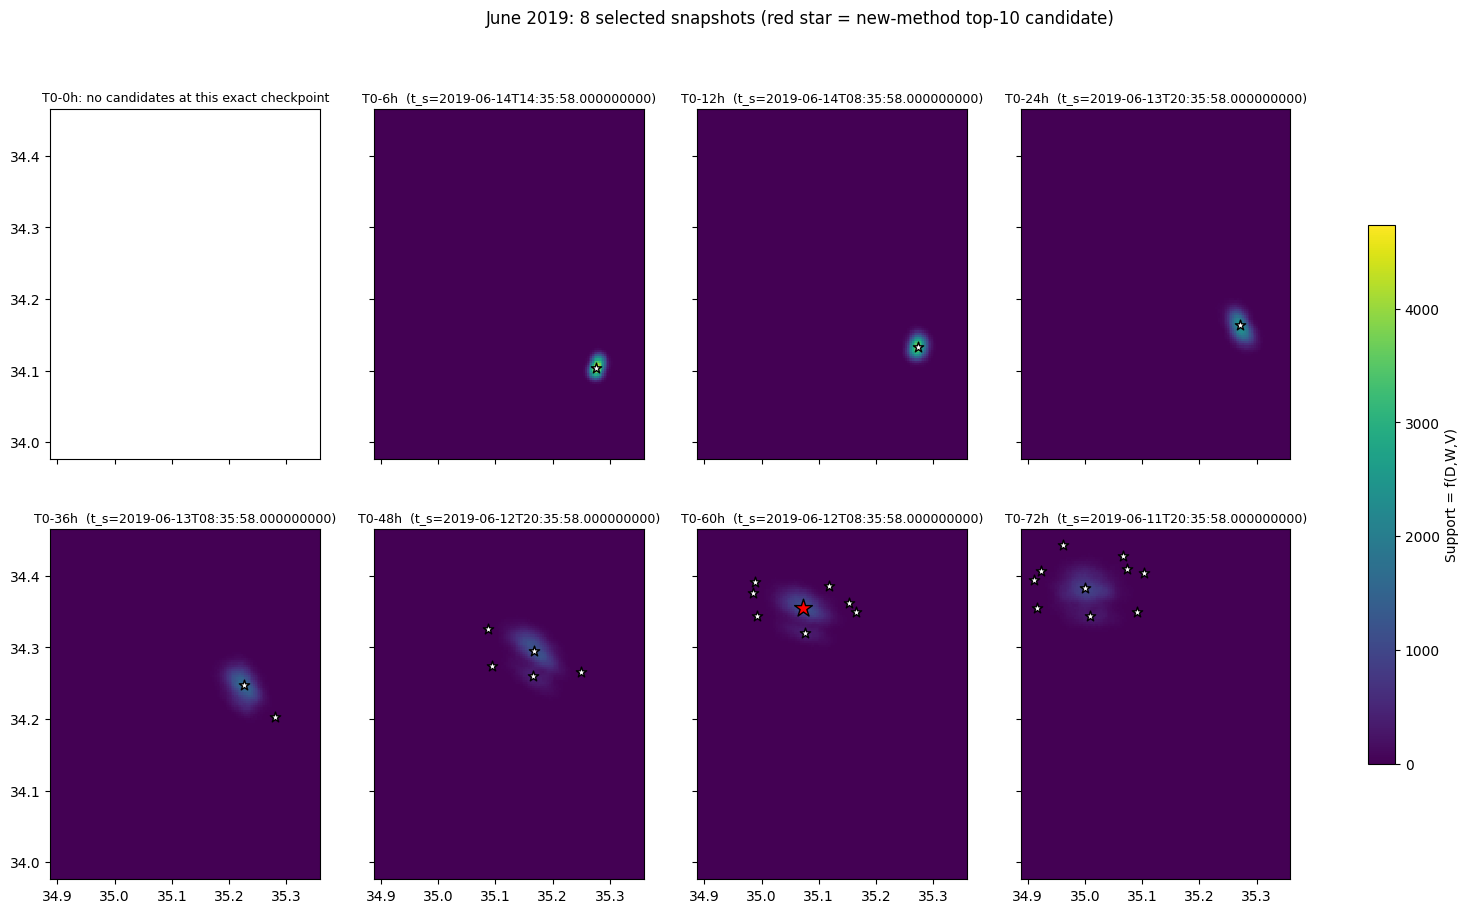

In [7]:
snapshot_offsets_h = [0, 6, 12, 24, 36, 48, 60, 72]
snapshot_t_s = [t_obs - np.timedelta64(h, "h") for h in snapshot_offsets_h]
fig, axes = plt.subplots(2, 4, figsize=(20, 10), sharex=True, sharey=True)
axes = axes.ravel()
vmax = max(g.max() for g in support_grids_by_t_s.values())
for ax, t_s, h in zip(axes, snapshot_t_s, snapshot_offsets_h):
    grid_vals = support_grids_by_t_s.get(np.datetime64(t_s, "ns"))
    if grid_vals is None:
        ax.set_title(f"T0-{h}h: no candidates at this exact checkpoint", fontsize=9)
        continue
    mesh = ax.pcolormesh(support_lon_grid, support_lat_grid, grid_vals, shading="auto", cmap="viridis", vmin=0, vmax=vmax)
    cands_here = [c for c in all_candidates if np.datetime64(c.t_s, "ns") == np.datetime64(t_s, "ns")]
    for c in cands_here:
        is_new_top10 = c.candidate_id in new_top10_ids
        ax.scatter([c.x_peak], [c.y_peak], marker="*", s=180 if is_new_top10 else 60,
                   c="red" if is_new_top10 else "white", edgecolors="black", linewidths=1, zorder=5)
    ax.set_title(f"T0-{h}h  (t_s={np.datetime64(t_s,'ns')})", fontsize=9)
fig.colorbar(mesh, ax=axes, label="Support = f(D,W,V)", shrink=0.7)
fig.suptitle("June 2019: 8 selected snapshots (red star = new-method top-10 candidate)", fontsize=12)
fig.savefig(os.path.join(RESULT_DIR, "june2019_selected_snapshots.png"), dpi=100)
plt.show()

## 6. Final map -- observed slick, particle envelope, top clusters, uncertainty radii

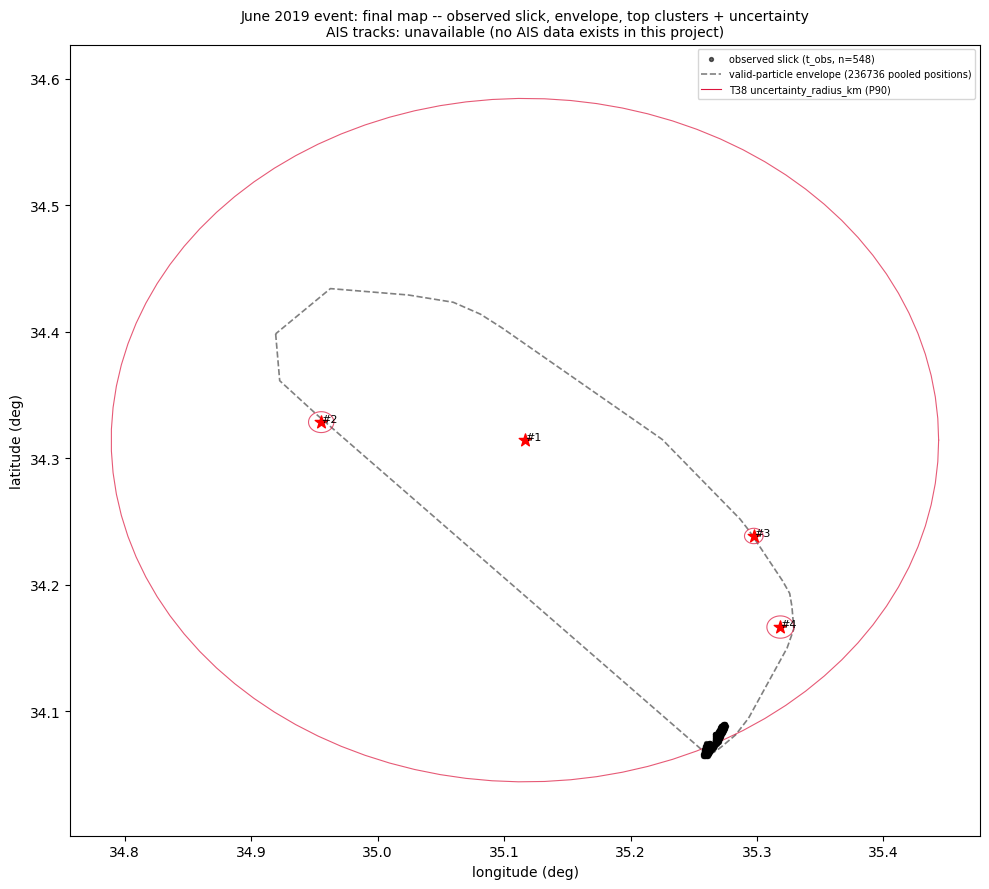

In [8]:
fig, ax = plt.subplots(figsize=(10, 9))
ax.scatter(obs_lon, obs_lat, c="black", s=8, alpha=0.6, label=f"observed slick (t_obs, n={len(parcels)})", zorder=6)

env_x, env_y = project_to_local_metres(envelope_lat, envelope_lon, lat_ref=obs_ref_lat, lon_ref=obs_ref_lon)
try:
    hull = ConvexHull(np.column_stack([env_x, env_y]))
    hull_idx = list(hull.vertices) + [hull.vertices[0]]
    ax.plot(envelope_lon[hull_idx], envelope_lat[hull_idx], color="gray", linewidth=1.2, linestyle="--",
            label=f"valid-particle envelope ({len(envelope_lat)} pooled positions)", zorder=2)
except QhullError:
    print("particle envelope convex hull degenerate; skipping")

def _circle_lonlat(radius_m, lat_ref, lon_ref, n=100):
    theta = np.linspace(0, 2 * np.pi, n)
    x_m = radius_m * np.cos(theta); y_m = radius_m * np.sin(theta)
    dlat = y_m / 111320.0
    dlon = x_m / (111320.0 * np.cos(np.radians(lat_ref)))
    return lon_ref + dlon, lat_ref + dlat

top10_clusters = clusters[:10]
for rank, cl in enumerate(top10_clusters, start=1):
    unc = uncertainty_by_cluster[cl.cluster_id]
    ax.scatter([cl.centroid_lon], [cl.centroid_lat], s=90, c="red", marker="*", zorder=7)
    ax.annotate(f"#{rank}", (cl.centroid_lon, cl.centroid_lat), fontsize=8, zorder=8)
    lon_c, lat_c = _circle_lonlat(unc.uncertainty_radius_km * 1000.0, cl.centroid_lat, cl.centroid_lon)
    ax.plot(lon_c, lat_c, color="crimson", linewidth=0.8, alpha=0.7, zorder=4)
ax.plot([], [], color="crimson", linewidth=0.8, label="T38 uncertainty_radius_km (P90)")
ax.set_xlabel("longitude (deg)"); ax.set_ylabel("latitude (deg)")
ax.set_title("June 2019 event: final map -- observed slick, envelope, top clusters + uncertainty\n"
             "AIS tracks: unavailable (no AIS data exists in this project)", fontsize=10)
ax.legend(fontsize=7, loc="best")
ax.set_aspect("equal", adjustable="datalim")
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "june2019_final_map.png"), dpi=110)
plt.show()

## 7. Validation + summary

In [9]:
checks = []
checks.append(("73 T0..T72 analysis timestamps", len(grid) == 73))
checks.append(("T0 == 2019-06-14T20:35:58", grid[0] == np.datetime64("2019-06-14T20:35:58", "ns")))
checks.append(("T72 == 2019-06-11T20:35:58", grid[-1] == np.datetime64("2019-06-11T20:35:58", "ns")))
checks.append(("no October timestamps anywhere in the grid", not any(str(t)[:7] == "2019-10" for t in grid)))
checks.append(("every candidate accounted for exactly once in clustering",
               sum(cl.n_members for cl in clusters) == len(all_candidates)))
checks.append(("AIS reported unavailable, never fabricated",
               all(r.ais_status == "unavailable" for r in uncertainty_table)))
for label, ok in checks:
    print(f"[{'OK' if ok else 'FAIL'}] {label}")
assert all(ok for _, ok in checks)

summary = {
    "event": "June 2019 (ow-0008.jpg)",
    "t_obs": str(grid[0]), "t72": str(grid[-1]),
    "n_particles": 548, "n_forcing_members": 6,
    "n_records": int(records.n_records),
    "n_candidates": len(all_candidates), "n_clusters": len(clusters),
    "top10_overlap_old_vs_new": len(old_top10_ids & new_top10_ids),
}
with open(os.path.join(RESULT_DIR, "june2019_run_summary.json"), "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)
print(json.dumps(summary, indent=2))

[OK] 73 T0..T72 analysis timestamps
[OK] T0 == 2019-06-14T20:35:58
[OK] T72 == 2019-06-11T20:35:58
[OK] no October timestamps anywhere in the grid
[OK] every candidate accounted for exactly once in clustering
[OK] AIS reported unavailable, never fabricated
{
  "event": "June 2019 (ow-0008.jpg)",
  "t_obs": "2019-06-14T20:35:58.000000000",
  "t72": "2019-06-11T20:35:58.000000000",
  "n_particles": 548,
  "n_forcing_members": 6,
  "n_records": 240024,
  "n_candidates": 271,
  "n_clusters": 4,
  "top10_overlap_old_vs_new": 0
}
